In [116]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [117]:
df = pd.read_csv("/content/Superstore_clean.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Quarter,Profit Margin (%)
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,4,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,4,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,2,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,4,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,4,11.25


# **0. Executive Summary**


- sales performance analysis shows the overall revenue trend and identifies key contributors by region and customer segment.
- customer analysis highlights important customer segments and valuable customers based on purchasing behavior.
- product analysis identifies top-performing categories and purchasing relationships between products through market basket analysis.
- discount analysis shows that higher discount levels may negatively impact profitability, requiring careful evaluation of pricing strategies.

# **1. KPI**

In [118]:
total_sales = df["Sales"].sum()
total_sales

np.float64(2297200.8603000003)

In [119]:
total_profit =df["Profit"].sum()
total_profit

np.float64(286397.0217)

In [120]:
total_orders = df["Order ID"].nunique()
total_orders

5009

In [121]:
total_customers = df["Customer ID"].nunique()
total_customers

793

In [122]:
avg_order_value = total_sales / total_orders
avg_order_value

np.float64(458.61466566180883)

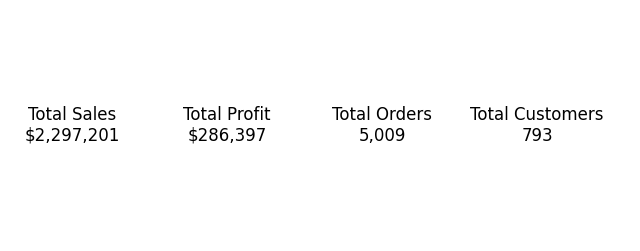

In [203]:
# visualisasi KPI

fig, ax = plt.subplots(figsize=(8,3))

ax.axis("off")

kpis = [
    ("Total Sales", f"${df['Sales'].sum():,.0f}"),
    ("Total Profit", f"${df['Profit'].sum():,.0f}"),
    ("Total Orders", f"{df['Order ID'].nunique():,}"),
    ("Total Customers", f"{df['Customer ID'].nunique():,}")
]

for i, (title, value) in enumerate(kpis):
    ax.text(
        i/4 + 0.1,
        0.5,
        f"{title}\n{value}",
        ha="center",
        va="center",
        fontsize=12
    )

plt.show()

# **2. Sales Performance Analysis**

In [123]:
# sales by year

sales_by_year = df.groupby("Year")["Sales"].sum()
sales_by_year

,Sales
Year,
2014,484247.4981
2015,470532.5090
2016,609205.5980
2017,733215.2552


### Sales trend insight

- sales performance showed an overall upward trend from 2014 to 2017
- revenue increased by approximately 61% from 2014 to 2017
- a slight decline occured in 2015 before sales growth accelerated in 2016 and reached the highest point in 2017
- further analysis will investigate regional, customer, and product factors contributing to sales growth

In [124]:
# sales by month

sales_by_month = df.groupby(["Month", "Month Name"])["Sales"].sum().sort_index()
sales_by_month

,,Sales
Month,Month Name,
1,January,94924.8356
2,February,59751.2514
3,March,205005.4888
4,April,137762.1286
5,May,155028.8117
6,June,152718.6793
7,July,147238.0970
8,August,159044.0630
9,September,307649.9457


In [211]:
top_month = sales_trend.sort_values(ascending=False).head(5)
top_month

,Sales
Order Date,
2017-11,118447.8250
2016-12,96999.0430
2017-09,87866.6520
2017-12,83829.3188
2014-09,81777.3508


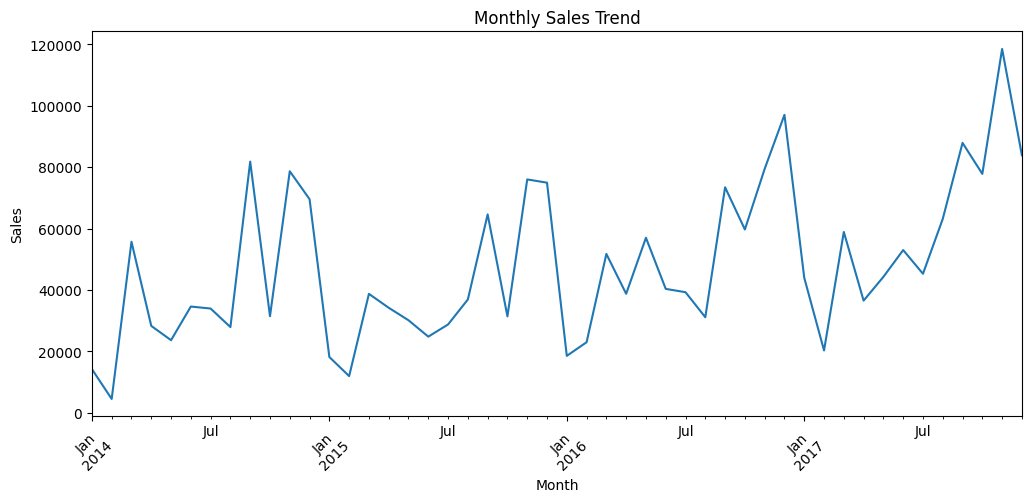

In [205]:
sales_trend = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
plt.figure(figsize=(12,5))
sales_trend.plot()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

### Monthly Sales Trend Insight

- sales showed a fluctuating pattern from 2014 to 2017, with several monthly peaks and declines throughout the period.
- overall sales performance increased over time, with higher revenue peaks observed in the later years.
- the highest sales peak occurred in November 2017 with approximately 118K in sales.
- monthly fluctuations indicate potential seasonal patterns in customer purchasing behavior.

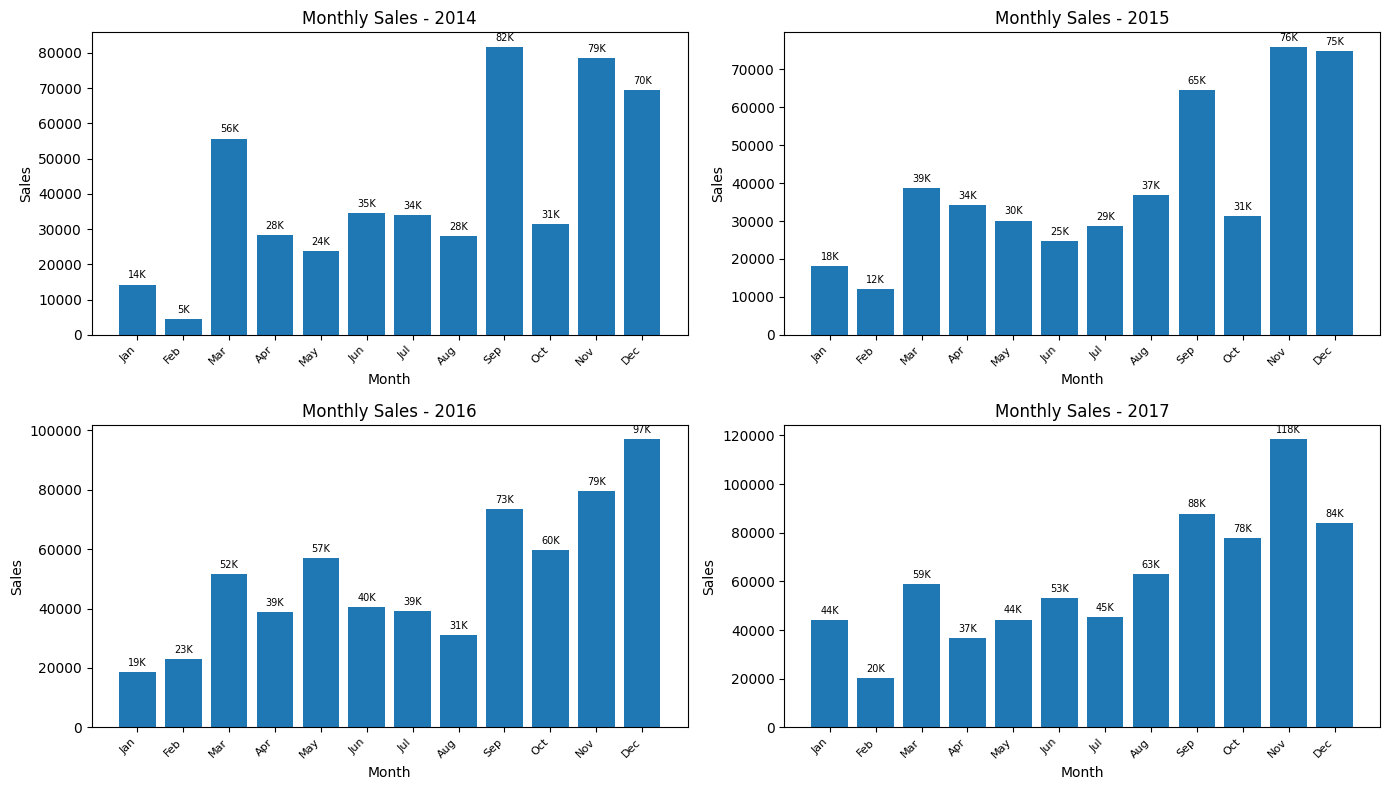

In [215]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(2, 2, figsize=(14,8))
years = sorted(df["Year"].unique())

for ax, year in zip(axes.flatten(), years):

    yearly_sales = df[df["Year"] == year].groupby("Month")["Sales"].sum()

    bars = ax.bar(yearly_sales.index,yearly_sales.values)
    ax.bar_label(bars,labels=[f"{x/1000:.0f}K" for x in yearly_sales.values], padding=3,fontsize=7)

    ax.set_title(f"Monthly Sales - {year}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales")

    ax.set_xticks(range(1,13))
    ax.set_xticklabels(
        month_labels,
        rotation=45,
        ha="right",
        fontsize=8)

plt.tight_layout()
plt.show()

### Monthly Sales Comparison by Year Insight

- sales performance increased year by year, with 2017 showing the highest monthly sales contribution.
- higher sales activity was consistently observed during the last quarter, especially around november and december.
- november 2017 generated the highest monthly sales across the analyzed period with approximately 118K in revenue.
- the growth of monthly sales peaks indicates improving business performance from 2014 to 2017.

In [125]:
# sales by region

sales_by_region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
sales_by_region

,Sales
Region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050


In [126]:
region_performance = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
region_performance

,Sales,Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
Central,501239.8908,39706.3625
South,391721.9050,46749.4303


In [127]:
region_performance["Profit Margin (%)"] = (region_performance["Profit"] / region_performance["Sales"]) *100
region_performance

,Sales,Profit,Profit Margin (%)
Region,,,
West,725457.8245,108418.4489,14.944831
East,678781.2400,91522.7800,13.483399
Central,501239.8908,39706.3625,7.921629
South,391721.9050,46749.4303,11.934342


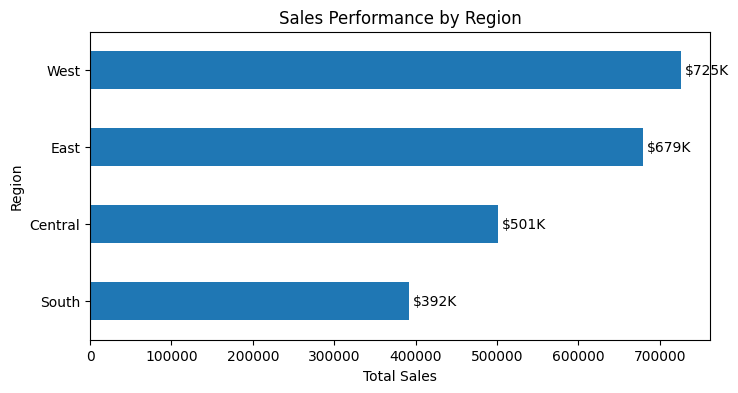

In [221]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values()

plt.figure(figsize=(8,4))
region_sales.plot(kind="barh")

plt.title("Sales Performance by Region")
plt.xlabel("Total Sales")
plt.ylabel("Region")

plt.bar_label(bars, labels=[f"${x/1000:.0f}K" for x in region_sales.values], padding=3)
plt.show()

### Sales by Region Insight

- sales contribution varies significantly across regions, indicating differences in regional market performance.
- west region generated the highest sales contribution, followed by East, Central, and South regions.
- west and East regions represent the strongest revenue contributors, suggesting higher customer demand in these markets.
- the difference in regional sales performance highlights opportunities to evaluate customer distribution and market potential across regions.

In [128]:
# sales by segment

sales_by_segment = df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
sales_by_segment

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


In [129]:
sales_by_segment["Profit Margin (%)"] = (sales_by_segment["Profit"] / sales_by_segment["Sales"]) *100
sales_by_segment

,Sales,Profit,Profit Margin (%)
Segment,,,
Consumer,1.161401e+06,134119.2092,11.548050
Corporate,7.061464e+05,91979.1340,13.025506
Home Office,4.296531e+05,60298.6785,14.034269


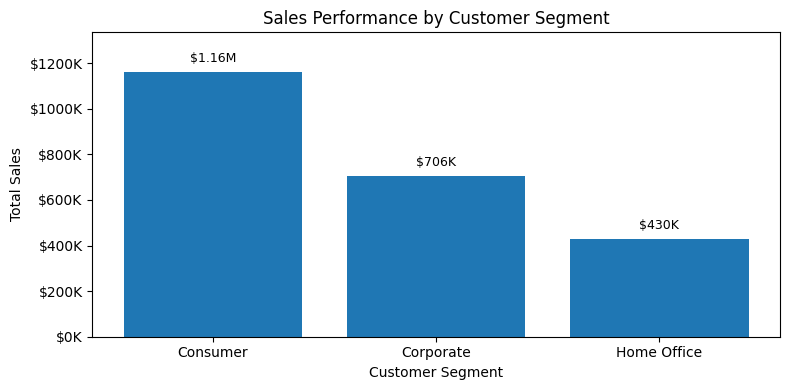

In [226]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,4))
bars = plt.bar(segment_sales.index, segment_sales.values)

plt.title("Sales Performance by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.bar_label(
    bars,
    labels=[
        f"${x/1_000_000:.2f}M" if x >= 1_000_000
        else f"${x/1000:.0f}K"
        for x in segment_sales.values
    ],
    padding=5,
    fontsize=9
)

plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K))

plt.ylim(0, segment_sales.max() * 1.15)
plt.tight_layout()
plt.show()

### Sales by Customer Segment Insight

- consumer segment generated the highest sales with approximately 1.16M, followed by Corporate 706K and Home Office 430K.
- consumer customers represent the largest revenue contributor, indicating stronger purchasing activity compared to other segments.
- sales contribution varies significantly across customer segments, highlighting differences in customer demand and purchasing behavior.

# **3. Customer & Geographic Analysis**

In [130]:
# customer overview

total_customer = df["Customer ID"].nunique()
total_customer

793

### Customer overview insight

- the dataset contains 793 unique customer across different customer segments
- understanding customer distribution is important to identify the primary customer groups contributing to business performance

In [131]:
# customer by segment

customer_by_segment = df.groupby("Segment")["Customer ID"].nunique().sort_values(ascending=False)
customer_by_segment

,Customer ID
Segment,
Consumer,409
Corporate,236
Home Office,148


### customer segment insight

- consumer segment has the largest customer base with 409 customers, followed by corporate with 236 customers and home office with 148 customers
- the dominance of cunsomer customers indicates that individual customers represent the company's largest market segment
- this pattern is consistent with previous sales analysis, where consumer segment also generated the highest sales contribution
- further analysis is needed to evaluate customer value and purchasing behavior across segments

In [132]:
# top customer by sales

top_customer = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False)
top_customer.head(10)

,Sales
Customer Name,
Sean Miller,25043.050
Tamara Chand,19052.218
Raymond Buch,15117.339
Tom Ashbrook,14595.620
Adrian Barton,14473.571
Ken Lonsdale,14175.229
Sanjit Chand,14142.334
Hunter Lopez,12873.298
Sanjit Engle,12209.438


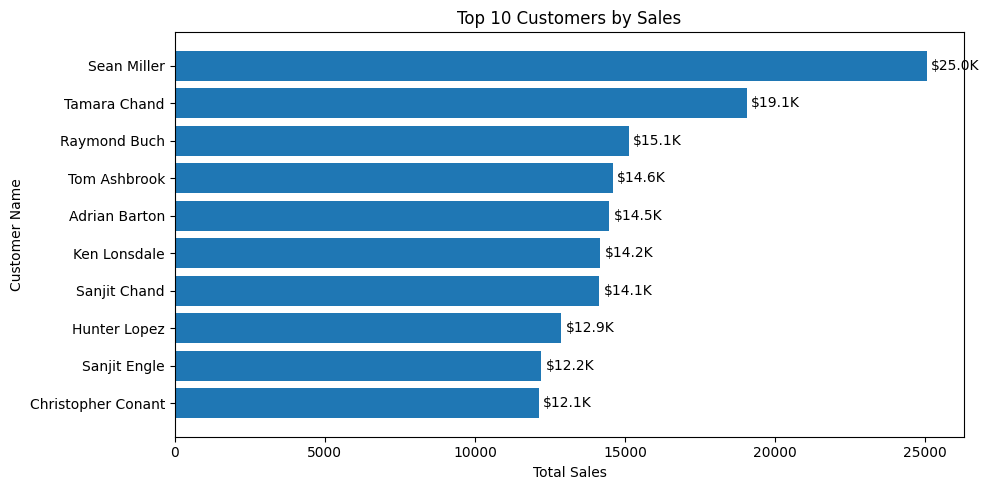

In [229]:
import matplotlib.pyplot as plt

top_customer = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))

bars = plt.barh(
    top_customer.index[::-1],
    top_customer.values[::-1]
)


plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")


plt.bar_label(
    bars,
    labels=[
        f"${x/1000:.1f}K"
        for x in top_customer.values[::-1]
    ],
    padding=3
)


plt.tight_layout()
plt.show()

### Top Customer by Sales Insight

- Sean Miller is the highest-value customer with total sales of approximately 25K, followed by Tamara Chand with approximately 19K.
- the top customers show differences in purchasing value, indicating variations in customer contribution to overall revenue.
- identifying high-value customers helps understand important customer segments and supports customer retention strategies.

In [133]:
# customer contribution analysis

top10_sales = top_customer.head(10).sum()
total_sales = df["Sales"].sum()
contribution = (top10_sales / total_sales) * 100
contribution

np.float64(6.695590779985744)

### customer contribution insight

- the top 10 customers contributed approcimately 6.7% of total sales
- the indicates that sales are relatively distributed across the customer base, with no strong dependency on a small group of customers
- althought some customers generate higher individual sales, maintaining a broad customer base remains important for sustainable revenue growth

In [134]:
# customer by region

customer_by_region = df.groupby("Region")["Customer ID"].nunique().sort_values(ascending=False)
customer_by_region

,Customer ID
Region,
West,686
East,674
Central,629
South,512


## customer by region insight

- west region has the largest customer base with 686 customers, followed by east with 674 customers
- south region has the lowest number of customers with 512
- the distribution shows that customers are relatively spread across regions, with west and east representating the largest customer markets

In [135]:
# customer by state

customer_by_state = df.groupby("State")["Customer ID"].nunique().sort_values(ascending=False).head(10)
customer_by_state

,Customer ID
State,
California,577
New York,415
Texas,370
Pennsylvania,257
Illinois,237
Washington,224
Ohio,202
Florida,181
North Carolina,122


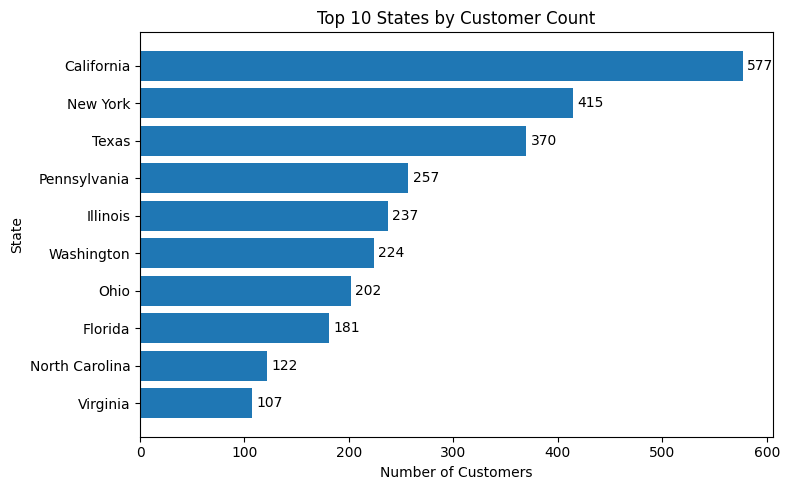

In [228]:
top_state = customer_by_state.head(10)

plt.figure(figsize=(8,5))

bars = plt.barh(
    top_state.index[::-1],
    top_state.values[::-1]
)


plt.title("Top 10 States by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("State")


plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

### Customer Distribution by State Insight

- california has the largest customer base with 577 unique customers, followed by New York with 415 and Texas with 370 customers.
- customer distribution varies considerably across states, indicating different levels of customer presence across geographic markets.
- california, New York, and Texas represent the largest customer markets among the analyzed states.
- the concentration of customers in specific states highlights regions with stronger market presence and potential opportunities for further business analysis.

In [136]:
df["Order Date"].max()

'2017-12-30'

In [137]:
df["Order Date"].dtype

dtype('O')

In [138]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [139]:
df["Order Date"].dtype

dtype('<M8[ns]')

In [140]:
reference_date = df["Order Date"].max() + pd.Timedelta(days=1)
reference_date

Timestamp('2017-12-31 00:00:00')

## **RFM Customer Segmentation**

In [141]:
last_purchase = df.groupby("Customer ID")["Order Date"].max()
last_purchase.head(10)

,Order Date
Customer ID,
AA-10315,2017-06-29
AA-10375,2017-12-11
AA-10480,2017-04-15
AA-10645,2017-11-05
AB-10015,2016-11-10
AB-10060,2017-11-06
AB-10105,2017-11-19
AB-10150,2017-11-19
AB-10165,2017-12-05


In [142]:
recency = (reference_date - last_purchase).dt.days
recency.head(10)

,Order Date
Customer ID,
AA-10315,185
AA-10375,20
AA-10480,260
AA-10645,56
AB-10015,416
AB-10060,55
AB-10105,42
AB-10150,42
AB-10165,26


In [143]:
frequency = df.groupby("Customer ID")["Order ID"].nunique()
frequency.head(10)

,Order ID
Customer ID,
AA-10315,5
AA-10375,9
AA-10480,4
AA-10645,6
AB-10015,3
AB-10060,8
AB-10105,10
AB-10150,5
AB-10165,8


In [144]:
monetary = df.groupby("Customer ID")["Sales"].sum()
monetary.head(10)

,Sales
Customer ID,
AA-10315,5563.560
AA-10375,1056.390
AA-10480,1790.512
AA-10645,5086.935
AB-10015,886.156
AB-10060,7755.620
AB-10105,14473.571
AB-10150,966.710
AB-10165,1113.838


In [145]:
rfm = pd.DataFrame({"Recency": recency, "Frequency": frequency, "Monetary": monetary})
rfm.head(10)

,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
AB-10060,55,8,7755.620
AB-10105,42,10,14473.571
AB-10150,42,5,966.710
AB-10165,26,8,1113.838


In [146]:
rfm.describe()

,Recency,Frequency,Monetary
count,793.000000,793.000000,793.000000
mean,147.802018,6.316520,2896.848500
std,186.211051,2.550885,2628.670117
min,1.000000,1.000000,4.833000
25%,31.000000,5.000000,1146.050000
50%,76.000000,6.000000,2256.394000
75%,184.000000,8.000000,3785.276000
max,1166.000000,17.000000,25043.050000


In [147]:
rfm = rfm.reset_index()
rfm.head(10)

,Customer ID,Recency,Frequency,Monetary
0,AA-10315,185,5,5563.560
1,AA-10375,20,9,1056.390
2,AA-10480,260,4,1790.512
3,AA-10645,56,6,5086.935
4,AB-10015,416,3,886.156
5,AB-10060,55,8,7755.620
6,AB-10105,42,10,14473.571
7,AB-10150,42,5,966.710
8,AB-10165,26,8,1113.838
9,AB-10255,167,9,914.532


In [148]:
rfm.shape

(793, 4)

In [149]:
rfm["RScore"] = pd.qcut(rfm["Recency"], q=4, labels=[4, 3, 2, 1])  #paling aktif, cukup baru, agak lama, paling lama
rfm[["Customer ID", "Recency", "RScore"]].head(10)

,Customer ID,Recency,RScore
0,AA-10315,185,1
1,AA-10375,20,4
2,AA-10480,260,1
3,AA-10645,56,3
4,AB-10015,416,1
5,AB-10060,55,3
6,AB-10105,42,3
7,AB-10150,42,3
8,AB-10165,26,4
9,AB-10255,167,2


In [150]:
rfm["MScore"] = pd.qcut(rfm["Monetary"], q=4, labels=[1, 2, 3, 4]) #spending rendah, agak rendah, cukup tinggi, spending tinggi
rfm[["Customer ID", "Monetary", "MScore"]].head(10)

,Customer ID,Monetary,MScore
0,AA-10315,5563.560,4
1,AA-10375,1056.390,1
2,AA-10480,1790.512,2
3,AA-10645,5086.935,4
4,AB-10015,886.156,1
5,AB-10060,7755.620,4
6,AB-10105,14473.571,4
7,AB-10150,966.710,1
8,AB-10165,1113.838,1
9,AB-10255,914.532,1


In [151]:
rfm["FRank"] = rfm["Frequency"].rank(method="first")

rfm["FScore"] = pd.qcut(rfm["FRank"], q=4, labels=[1, 2, 3, 4]) #frequency rendah, agak rendah, cukup tinggi, paling tinggi
rfm[["Customer ID", "Frequency", "FScore"]].head(10)

,Customer ID,Frequency,FScore
0,AA-10315,5,1
1,AA-10375,9,4
2,AA-10480,4,1
3,AA-10645,6,2
4,AB-10015,3,1
5,AB-10060,8,3
6,AB-10105,10,4
7,AB-10150,5,1
8,AB-10165,8,3
9,AB-10255,9,4


In [152]:
rfm["RFMScore"] = (
    rfm["RScore"].astype(str) +
    rfm["FScore"].astype(str) +
    rfm["MScore"].astype(str))

rfm[["Customer ID", "Recency", "Frequency", "Monetary", "RScore", "FScore", "MScore", "RFMScore"]].head(10)

,Customer ID,Recency,Frequency,Monetary,RScore,FScore,MScore,RFMScore
0,AA-10315,185,5,5563.560,1,1,4,114
1,AA-10375,20,9,1056.390,4,4,1,441
2,AA-10480,260,4,1790.512,1,1,2,112
3,AA-10645,56,6,5086.935,3,2,4,324
4,AB-10015,416,3,886.156,1,1,1,111
5,AB-10060,55,8,7755.620,3,3,4,334
6,AB-10105,42,10,14473.571,3,4,4,344
7,AB-10150,42,5,966.710,3,1,1,311
8,AB-10165,26,8,1113.838,4,3,1,431
9,AB-10255,167,9,914.532,2,4,1,241


In [153]:
def rfm_segment(row):
    r = int(row["RScore"])
    f = int(row["FScore"])
    m = int(row["MScore"])

    if r >= 3 and f >= 3 and m >= 3:
        return "Champions"

    elif r >= 3 and f >= 3 and m < 3:
        return "Loyal Customers"

    elif r >= 3 and f <= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3 and m >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Hibernating"

    else:
        return "Need Attention"

rfm["Customer Segment"] = rfm.apply(rfm_segment, axis=1)

In [154]:
rfm[["Customer ID", "RScore", "FScore", "MScore", "RFMScore", "Customer Segment"]].head(10)

,Customer ID,RScore,FScore,MScore,RFMScore,Customer Segment
0,AA-10315,1,1,4,114,Hibernating
1,AA-10375,4,4,1,441,Loyal Customers
2,AA-10480,1,1,2,112,Hibernating
3,AA-10645,3,2,4,324,Potential Loyalists
4,AB-10015,1,1,1,111,Hibernating
5,AB-10060,3,3,4,334,Champions
6,AB-10105,3,4,4,344,Champions
7,AB-10150,3,1,1,311,Potential Loyalists
8,AB-10165,4,3,1,431,Loyal Customers
9,AB-10255,2,4,1,241,Need Attention


In [155]:
segment_summary = rfm["Customer Segment"].value_counts()
segment_summary

,count
Customer Segment,
Hibernating,238
Champions,176
Potential Loyalists,159
At Risk,107
Loyal Customers,62
Need Attention,51


In [156]:
segment_performance = (rfm.groupby("Customer Segment").agg(
        Customers=("Customer ID", "nunique"),
        Total_Monetary=("Monetary", "sum"),
        Avg_Monetary=("Monetary", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Recency=("Recency", "mean")).sort_values("Total_Monetary", ascending=False))

segment_performance

,Customers,Total_Monetary,Avg_Monetary,Avg_Frequency,Avg_Recency
Customer Segment,,,,,
Champions,176,802935.4674,4562.133337,8.806818,33.232955
At Risk,107,530689.6300,4959.716168,8.308411,170.616822
Hibernating,238,437189.8963,1836.932337,4.130252,316.500000
Potential Loyalists,159,357340.1649,2247.422421,4.515723,34.962264
Loyal Customers,62,98896.2932,1595.101503,7.774194,31.064516
Need Attention,51,70149.4085,1375.478598,7.588235,201.764706


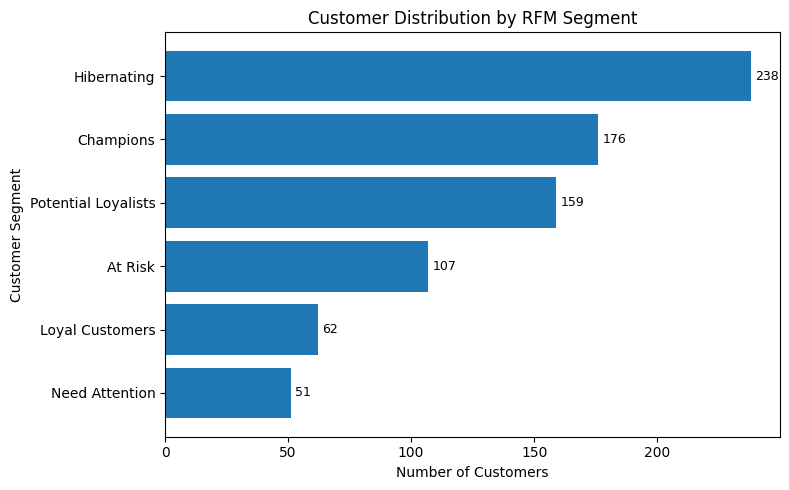

In [236]:
import matplotlib.pyplot as plt


rfm_segment = (
    rfm["Customer Segment"]
    .value_counts()
    .sort_values(ascending=True)
)


plt.figure(figsize=(8,5))


bars = plt.barh(
    rfm_segment.index,
    rfm_segment.values
)


plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")


plt.bar_label(
    bars,
    padding=3,
    fontsize=9
)


plt.tight_layout()
plt.show()

### RFM Customer Segment Insight

- hibernating is the largest customer segment with 238 customers, followed by Champions 176 and Potential Loyalists 159.
- the high number of Hibernating customers indicates many customers have reduced purchasing activity and may require re-engagement strategies.
- champions and Potential Loyalists represent valuable customer groups with stronger engagement and potential for retention.

In [238]:
rfm_revenue = (
    df.merge(
        rfm[["Customer ID","Customer Segment"]],
        on="Customer ID"
    )
    .groupby("Customer Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)


rfm_revenue

,Sales
Customer Segment,
Champions,802935.4674
At Risk,530689.6300
Hibernating,437189.8963
Potential Loyalists,357340.1649
Loyal Customers,98896.2932
Need Attention,70149.4085


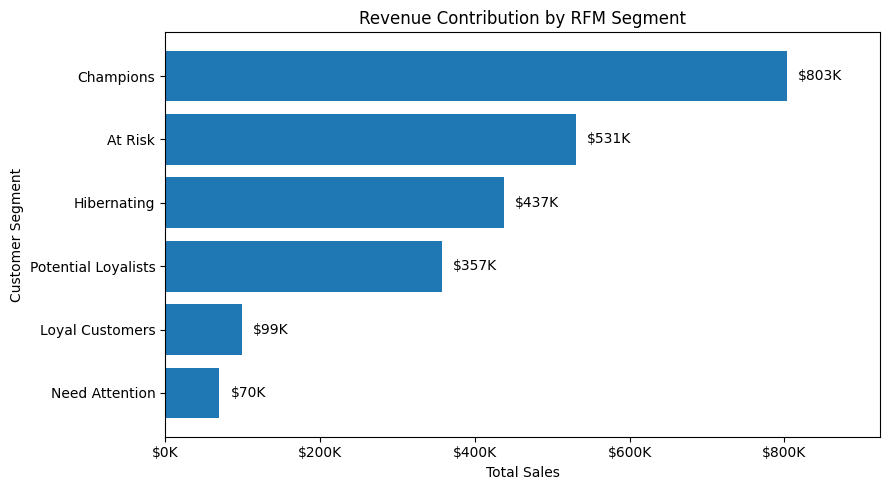

In [241]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

rfm_revenue = (
    rfm_sales
    .groupby("Customer Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9,5))

rfm_revenue_plot = rfm_revenue.sort_values(ascending=True)
bars = plt.barh(
    rfm_revenue_plot.index,
    rfm_revenue_plot.values
)

plt.title(
    "Revenue Contribution by RFM Segment",
    fontsize=14
)

plt.xlabel("Total Sales")
plt.ylabel("Customer Segment")
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1000:.0f}K")
)

plt.bar_label(
    bars,
    labels=[
        f"${x/1000:.0f}K"
        for x in rfm_revenue_plot.values
    ],
    padding=8,
    fontsize=10
)

plt.xlim(0, rfm_revenue_plot.max() * 1.15)
plt.tight_layout()
plt.show()

### Revenue Contribution by RFM Segment Insight

- champions contribute the highest revenue with approximately $803K in sales, followed by At Risk 531K and Hibernating 437K.
- high-value customers are concentrated in the Champions segment, indicating strong purchasing activity and customer value.
- the difference between customer distribution and revenue contribution shows that customer value varies across segments.

# **4. Product & Purchase Behavior**

In [157]:
# category performance

category_performance = df.groupby("Category").agg(
    Sales = ("Sales", "sum"),
    Profit = ("Profit", "sum"),
    Quantity = ("Quantity", "sum")).sort_values("Sales", ascending=False)

category_performance

,Sales,Profit,Quantity
Category,,,
Technology,836154.0330,145454.9481,6939
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906


In [158]:
category_performance["Profit Margin (%)"] = (category_performance["Profit"] / category_performance["Sales"]) * 100
category_performance

,Sales,Profit,Quantity,Profit Margin (%)
Category,,,,
Technology,836154.0330,145454.9481,6939,17.395712
Furniture,741999.7953,18451.2728,8028,2.486695
Office Supplies,719047.0320,122490.8008,22906,17.035158


In [244]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales

,Sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


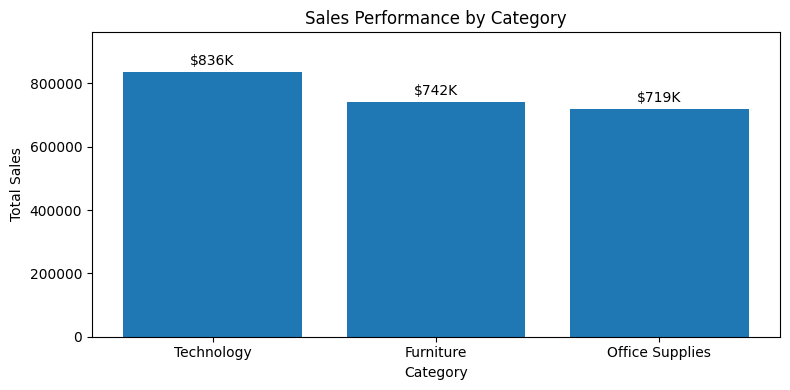

In [246]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
bars = plt.bar(
    category_sales.index,
    category_sales.values
)


plt.title("Sales Performance by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.bar_label(
    bars,
    labels=[
        f"${x/1000:.0f}K"
        for x in category_sales.values
    ],
    padding=3
)

plt.ylim(
    0,
    category_sales.max()*1.15
)

plt.tight_layout()
plt.show()

### Sales Performance by Category Insight

- technology generates the highest sales contribution with approximately $836K, followed by Furniture 742K and Office Supplies 719K.
- the three categories show relatively similar sales performance, with Technology slightly leading as the largest revenue contributor.
- category-level analysis highlights Technology as the primary driver of overall product sales.

In [159]:
# sub-category performance

subcategory_performance = df.groupby("Sub-Category").agg(
    Sales = ("Sales", "sum"),
    Profit = ("Profit", "sum"),
    Quantity = ("Quantity", "sum")).sort_values("Sales", ascending=False)

subcategory_performance["Pofit Margin (%)"] = (subcategory_performance["Profit"] / subcategory_performance["Sales"]) * 100
subcategory_performance

,Sales,Profit,Quantity,Pofit Margin (%)
Sub-Category,,,,
Phones,330007.0540,44515.7306,3289,13.489327
Chairs,328449.1030,26590.1663,2356,8.095673
Storage,223843.6080,21278.8264,3158,9.506113
Tables,206965.5320,-17725.4811,1241,-8.564460
Binders,203412.7330,30221.7633,5974,14.857361
Machines,189238.6310,3384.7569,440,1.788618
Accessories,167380.3180,41936.6357,2976,25.054700
Copiers,149528.0300,55617.8249,234,37.195585
Bookcases,114879.9963,-3472.5560,868,-3.022768


In [248]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)
subcategory_sales

,Sales
Sub-Category,
Phones,330007.0540
Chairs,328449.1030
Storage,223843.6080
Tables,206965.5320
Binders,203412.7330
Machines,189238.6310
Accessories,167380.3180
Copiers,149528.0300
Bookcases,114879.9963


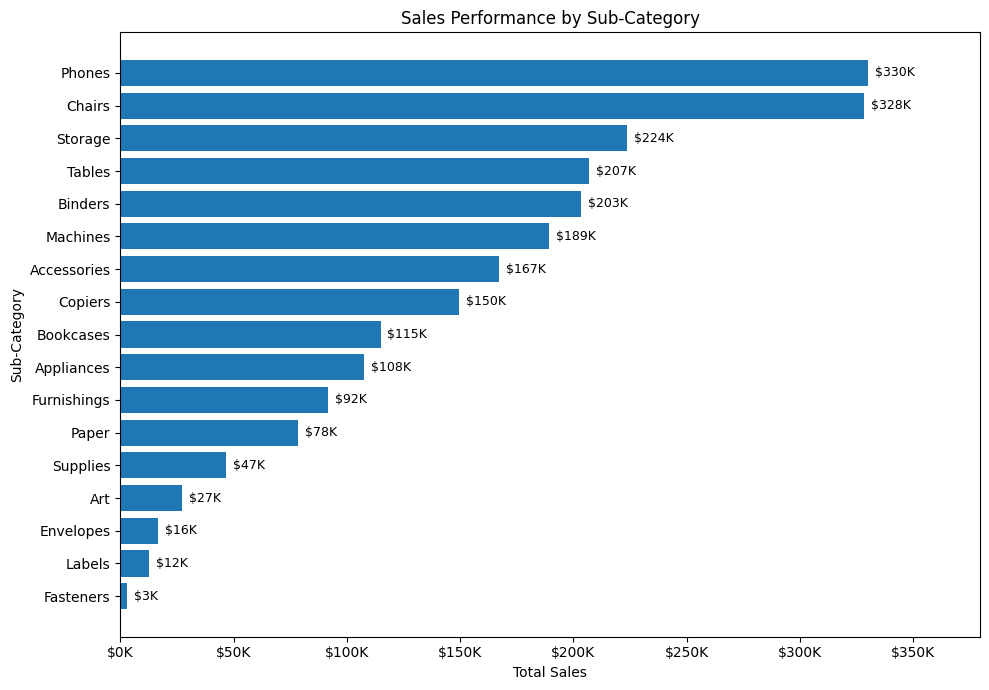

In [249]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

subcategory_sales_plot = (
    subcategory_sales
    .sort_values(ascending=True)
)

plt.figure(figsize=(10,7))

bars = plt.barh(
    subcategory_sales_plot.index,
    subcategory_sales_plot.values
)

plt.title("Sales Performance by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1000:.0f}K")
)

plt.bar_label(
    bars,
    labels=[
        f"${x/1000:.0f}K"
        for x in subcategory_sales_plot.values
    ],
    padding=5,
    fontsize=9
)

plt.xlim(
    0,
    subcategory_sales_plot.max()*1.15
)

plt.tight_layout()
plt.show()

### Sales Performance by Sub-Category Insight

- phones and chairs are the top-performing sub-categories with approximately 330K and 328K in sales respectively.
- several sub-categories including Storage, Tables, and Binders contribute significantly with sales above 200K.
- the results highlight that revenue is driven by a combination of technology and furniture-related products.

In [160]:
# top product by sales

top_product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
top_product_sales

,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


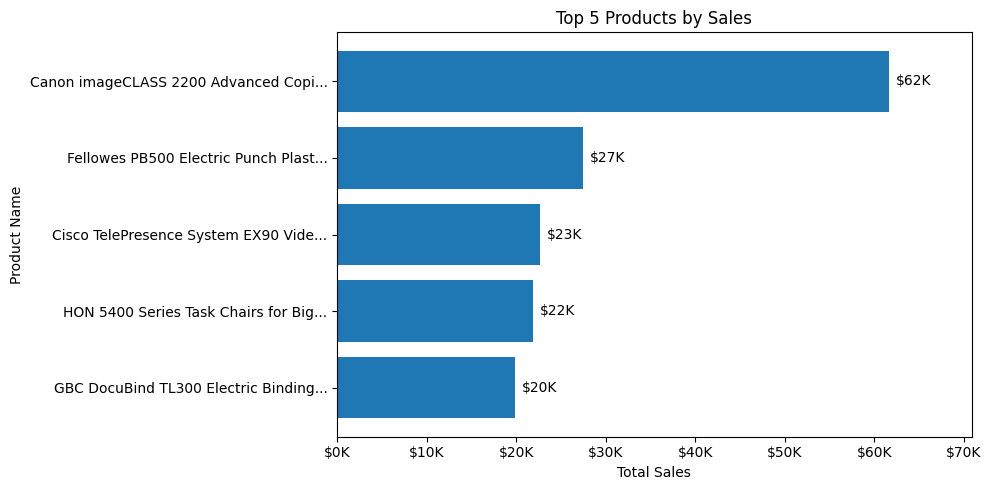

In [257]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

top_product_plot = (
    top_product_sales
    .head(5)
    .sort_values(ascending=True)
)

short_names = [
    name[:35] + "..." if len(name) > 35 else name
    for name in top_product_plot.index
]

plt.figure(figsize=(10,5))
bars = plt.barh(
    short_names,
    top_product_plot.values
)

plt.title("Top 5 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1000:.0f}K")
)

plt.bar_label(
    bars,
    labels=[
        f"${x/1000:.0f}K"
        for x in top_product_plot.values
    ],
    padding=5,
    fontsize=10
)

plt.xlim(
    0,
    top_product_plot.max()*1.15
)

plt.tight_layout()
plt.show()

### Top Product by Sales Insight

- canon imageCLASS 2200 Advanced Copier generates the highest sales contribution with approximately $62K, followed by Fellowes PB500 Electric Punch and Cisco TelePresence System EX90.
- top-performing products are primarily from technology and office equipment categories.
- sales contribution varies significantly across products, with Canon imageCLASS 2200 Advanced Copier showing a much higher performance compared to other products.

In [161]:
# top product by profit

top_product_profit = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)
top_product_profit

,Profit
Product Name,
Canon imageCLASS 2200 Advanced Copier,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,7753.0390
Hewlett Packard LaserJet 3310 Copier,6983.8836
Canon PC1060 Personal Laser Copier,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",4094.9766
Ativa V4110MDD Micro-Cut Shredder,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,3696.2820
Ibico EPK-21 Electric Binding System,3345.2823


In [162]:
# loss making products

bottom_products_profit = df.groupby("Product Name")["Profit"].sum().sort_values().head(10)
bottom_products_profit

,Profit
Product Name,
Cubify CubeX 3D Printer Double Head Print,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.1156
Bush Advantage Collection Racetrack Conference Table,-1934.3976
GBC DocuBind P400 Electric Binding System,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,-1299.1836
Balt Solid Wood Round Tables,-1201.0581


### Product Performance Insight

- canon imageCLASS 2200 Advanced Copier is the strongest-performing product, generating both the highest sales and the highest total profit.
- products with high sales do not always generate proportionally high profits, highlighting the importance of evaluating product performance using both revenue and profitability metrics.
- several individual products generated substantial losses, with Cubify CubeX 3D Printer Double Head Print recording the largest negative profit.
- loss-making products are found across multiple categories, indicating that strong category-level performance can mask underperforming individual products.
- several table-related products appear among the largest loss contributors, consistent with the negative profitability previously observed in the Tables sub-category.

In [163]:
# repeat purchase behavior

orders_per_customer = df.groupby("Customer ID")["Order ID"].nunique()
orders_per_customer.describe()

,Order ID
count,793.000000
mean,6.316520
std,2.550885
min,1.000000
25%,5.000000
50%,6.000000
75%,8.000000
max,17.000000


In [164]:
onetime_customers = (orders_per_customer == 1).sum()
repeat_customers = (orders_per_customer > 1 ).sum()

print(f"Number of one-time customers: {onetime_customers}")
print(f"Number of repeat customers: {repeat_customers}")

Number of one-time customers: 12
Number of repeat customers: 781


In [165]:
repeat_purchase_rate = repeat_customers / orders_per_customer.count() * 100
repeat_purchase_rate

np.float64(98.48675914249685)

### Repeat Purchase Behavior Insight

- 781 out of 793 customers made more than one order during the observation period, resulting in a repeat purchase rate of approximately 98.5%.
- only 12 customers were identified as one-time purchasers.
- customers placed an average of approximately 6.3 orders, with a median of 6 orders per customer.
- these results indicate that the customer base is strongly dominated by repeat purchasers rather than one-time buyers.

In [166]:
basket = df.groupby(["Order ID", "Sub-Category"])["Quantity"].sum().unstack().fillna(0)
basket.head(10)

Sub-Category,Accessories,Appliances,Art,Binders,Bookcases,Chairs,Copiers,Envelopes,Fasteners,Furnishings,Labels,Machines,Paper,Phones,Storage,Supplies,Tables
Order ID,,,,,,,,,,,,,,,,,
CA-2014-100006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0
CA-2014-100090,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
CA-2014-100293,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0
CA-2014-100328,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CA-2014-100363,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0
CA-2014-100391,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0
CA-2014-100678,3.0,0.0,2.0,0.0,0.0,3.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CA-2014-100706,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CA-2014-100762,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,5.0,0.0,0.0,0.0,0.0


### **transaction basket preparation**

The transaction matrix shows the quantity of each sub-category purchased within each order. Some transactions contain multiple units of the same sub-category and multiple product categories, indicating potential cross-category purchasing patterns that will be explored using association rule mining.

In [167]:
basket = basket > 0
basket.head(10)

Sub-Category,Accessories,Appliances,Art,Binders,Bookcases,Chairs,Copiers,Envelopes,Fasteners,Furnishings,Labels,Machines,Paper,Phones,Storage,Supplies,Tables
Order ID,,,,,,,,,,,,,,,,,
CA-2014-100006,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
CA-2014-100090,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
CA-2014-100293,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
CA-2014-100328,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False
CA-2014-100363,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False
CA-2014-100391,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
CA-2014-100678,True,False,True,False,False,True,False,True,False,False,False,False,False,False,False,False,False
CA-2014-100706,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
CA-2014-100762,False,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,False


In [168]:
basket.shape

(5009, 17)

In [169]:
item_frequency = basket.sum().sort_values(ascending=False)
item_frequency

,0
Sub-Category,
Binders,1316
Paper,1191
Furnishings,877
Phones,814
Storage,777
Art,731
Accessories,718
Chairs,576
Appliances,451


### product frequency analysis

- Binders is the most frequently purchased sub-category with 1,316 transactions, followed by **Paper** with 1,191 transactions.
- Office supply categories dominate transaction frequency, suggesting strong customer demand for these product types.
- Purchase frequency alone does not indicate profitability; further analysis is required to evaluate revenue contribution and product relationships.
- These frequent categories will be used as a foundation for identifying product associations through the Apriori algorithm.



In [170]:
basket.dtypes

,0
Sub-Category,
Accessories,bool
Appliances,bool
Art,bool
Binders,bool
Bookcases,bool
Chairs,bool
Copiers,bool
Envelopes,bool
Fasteners,bool


In [183]:
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)
frequent_itemsets.sort_values(by="support", ascending=False)

,support,itemsets
3,0.262727,(Binders)
12,0.237772,(Paper)
9,0.175085,(Furnishings)
13,0.162507,(Phones)
14,0.155121,(Storage)
...,...,...
62,0.010781,"(Tables, Paper)"
66,0.010781,"(Binders, Paper, Phones)"
67,0.010581,"(Binders, Paper, Storage)"
64,0.010381,"(Tables, Phones)"


### Frequent Itemset Analysis Insight

- binders and Paper are the most frequently occurring sub-categories, appearing in 26.27% and 23.78% of transactions respectively.
- binders and Paper is the most frequent product combination identified, with a support value of 5.49%.
- frequent itemsets indicate potential cross-category purchasing patterns that require further evaluation using association rules.

In [177]:
from mlxtend.frequent_patterns import association_rules

In [189]:
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)
rules.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Appliances),(Binders),0.090038,0.262727,0.025953,0.288248,1.097140,1.0,0.002298,1.035857,0.097300,0.079414,0.034616,0.193516
1,(Binders),(Appliances),0.262727,0.090038,0.025953,0.098784,1.097140,1.0,0.002298,1.009705,0.120090,0.079414,0.009612,0.193516
2,(Appliances),(Furnishings),0.090038,0.175085,0.015971,0.177384,1.013129,1.0,0.000207,1.002794,0.014241,0.064103,0.002787,0.134302
3,(Furnishings),(Appliances),0.175085,0.090038,0.015971,0.091220,1.013129,1.0,0.000207,1.001301,0.015710,0.064103,0.001299,0.134302
4,(Appliances),(Paper),0.090038,0.237772,0.021761,0.241685,1.016458,1.0,0.000352,1.005160,0.017793,0.071102,0.005134,0.166602
5,(Paper),(Appliances),0.237772,0.090038,0.021761,0.091520,1.016458,1.0,0.000352,1.001631,0.021242,0.071102,0.001628,0.166602
6,(Appliances),(Phones),0.090038,0.162507,0.015173,0.168514,1.036964,1.0,0.000541,1.007224,0.039173,0.063919,0.007173,0.130940
7,(Phones),(Appliances),0.162507,0.090038,0.015173,0.093366,1.036964,1.0,0.000541,1.003671,0.042563,0.063919,0.003657,0.130940
8,(Art),(Phones),0.145937,0.162507,0.024755,0.169631,1.043833,1.0,0.001040,1.008578,0.049168,0.087262,0.008505,0.160982
9,(Phones),(Art),0.162507,0.145937,0.024755,0.152334,1.043833,1.0,0.001040,1.007546,0.050140,0.087262,0.007490,0.160982


In [196]:
rules_filtered = rules[(rules["lift"] > 1.1) & (rules["confidence"] >= 0.15)]
rules_filtered.sort_values(by="lift", ascending=False).head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
36,"(Binders, Paper)",(Storage),0.054901,0.155121,0.010581,0.192727,1.242434,1.0,0.002065,1.046585,0.206463,0.053053,0.044511,0.130469
30,"(Binders, Paper)",(Phones),0.054901,0.162507,0.010781,0.196364,1.208336,1.0,0.001859,1.042129,0.182431,0.052174,0.040426,0.131351
32,"(Paper, Phones)",(Binders),0.034937,0.262727,0.010781,0.308571,1.174494,1.0,0.001602,1.066304,0.153948,0.037578,0.062181,0.174802
13,(Fasteners),(Paper),0.042923,0.237772,0.011779,0.274419,1.154125,1.0,0.001573,1.050507,0.139532,0.043801,0.048078,0.161978
31,"(Binders, Phones)",(Paper),0.039728,0.237772,0.010781,0.271357,1.141248,1.0,0.001334,1.046092,0.128887,0.040419,0.044061,0.158348
20,(Labels),(Storage),0.069076,0.155121,0.012178,0.176301,1.136537,1.0,0.001463,1.025713,0.129049,0.057439,0.025068,0.127404
38,"(Paper, Storage)",(Binders),0.035536,0.262727,0.010581,0.297753,1.133316,1.0,0.001245,1.049877,0.121968,0.036780,0.047507,0.169013
37,"(Binders, Storage)",(Paper),0.039728,0.237772,0.010581,0.266332,1.120114,1.0,0.001135,1.038927,0.111670,0.039641,0.037469,0.155416


### Association Rule Analysis Insight

- binders and paper show strong purchasing relationships with other categories, particularly Storage and phones, with lift values above 1.2.
- the combination of paper and phones has the highest confidence among identified rules, where 30.85% of transactions containing both products also include Binders.
- several product combinations demonstrate positive associations, indicating potential cross-selling opportunities across related categories.

In [197]:
rules_display = rules_filtered[["antecedents", "consequents", "support", "confidence", "lift"]]
rules_display

,antecedents,consequents,support,confidence,lift
13,(Fasteners),(Paper),0.011779,0.274419,1.154125
20,(Labels),(Storage),0.012178,0.176301,1.136537
30,"(Binders, Paper)",(Phones),0.010781,0.196364,1.208336
31,"(Binders, Phones)",(Paper),0.010781,0.271357,1.141248
32,"(Paper, Phones)",(Binders),0.010781,0.308571,1.174494
36,"(Binders, Paper)",(Storage),0.010581,0.192727,1.242434
37,"(Binders, Storage)",(Paper),0.010581,0.266332,1.120114
38,"(Paper, Storage)",(Binders),0.010581,0.297753,1.133316


### Market Basket Analysis Insight

- binders and paper appear as key products in multiple association rules, showing consistent purchasing relationships with other sub-categories.
- the combination of binders and paper shows potential cross-selling opportunities, particularly with Storage and Phones, with lift values above 1.2.
- paper and phones transactions have the highest confidence level, where 30.86% of transactions containing both products also include Binders.
- the identified association rules indicate potential product bundling and recommendation opportunities based on customer purchasing patterns.

# **5. Discount & Profitability Analysis**

In [198]:
df["Discount"].value_counts().sort_index()

,count
Discount,
0.00,4798
0.10,94
0.15,52
0.20,3657
0.30,227
0.32,27
0.40,206
0.45,11
0.50,66


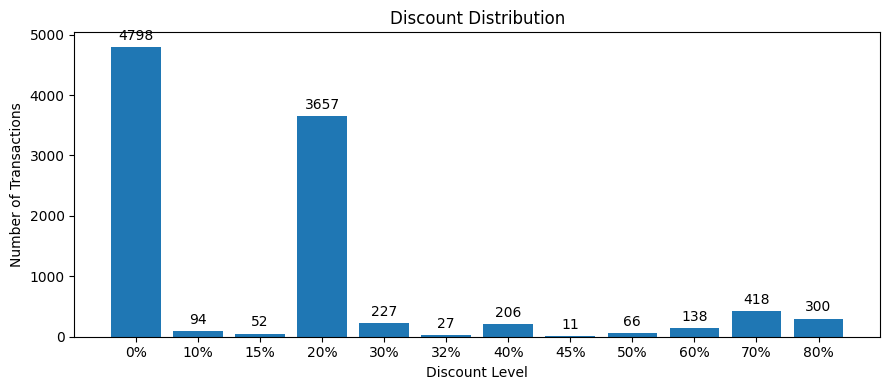

In [264]:
import matplotlib.pyplot as plt

discount_distribution = (
    df["Discount"]
    .value_counts()
    .sort_index()
)

labels = [
    f"{x:.0%}"
    for x in discount_distribution.index
]

plt.figure(figsize=(9,4))
bars = plt.bar(
    labels,
    discount_distribution.values
)

plt.title("Discount Distribution")
plt.xlabel("Discount Level")
plt.ylabel("Number of Transactions")
plt.bar_label(
    bars,
    padding=3
)

plt.tight_layout()
plt.show()

### Discount Distribution Insight

- most transactions were conducted with 0% and 20% discount levels, indicating that these discount strategies were the most frequently applied.
- higher discount levels such as 70% and 80% were applied to a smaller number of transactions, suggesting that aggressive discounting was used selectively.
- the variation in discount levels indicates different pricing strategies across transactions, which requires further analysis to evaluate their impact on sales and profitability.

In [199]:
discount_impact = (df.groupby("Discount").agg(
    total_sales = ("Sales", "sum"),
    total_profit = ("Profit", "sum"),
    avg_profit = ("Profit", "mean"),
    avg_sales = ("Sales", "mean"))). reset_index()

discount_impact

,Discount,total_sales,total_profit,avg_profit,avg_sales
0,0.00,1.087908e+06,320987.6032,66.900292,226.742074
1,0.10,5.436935e+04,9029.1770,96.055074,578.397351
2,0.15,2.755852e+04,1418.9915,27.288298,529.971567
3,0.20,7.645944e+05,90337.3060,24.702572,209.076940
4,0.30,1.032267e+05,-10369.2774,-45.679636,454.742974
5,0.32,1.449346e+04,-2391.1377,-88.560656,536.794770
6,0.40,1.164178e+05,-23057.0504,-111.927429,565.134874
7,0.45,5.484974e+03,-2493.1111,-226.646464,498.634000
8,0.50,5.891854e+04,-20506.4281,-310.703456,892.705152
9,0.60,6.644700e+03,-5944.6552,-43.077212,48.150000


### Discount Impact Analysis Insight

- transactions with 0% discount generated the highest total sales and profit contribution, indicating strong profitability without relying on price reductions.
- a 20% discount level still generated positive profit, but with lower average profit compared to non-discounted transactions.
- higher discount levels, particularly from 30% to 80%, resulted in negative total profit, indicating potential margin pressure from aggressive discount strategies.
- the analysis suggests that higher discounts do not always lead to higher profitability and should be evaluated based on their impact on profit contribution.

In [200]:
discount_impact["profit_margin"] = (discount_impact["total_profit"] / discount_impact["total_sales"]) * 100
discount_impact

,Discount,total_sales,total_profit,avg_profit,avg_sales,profit_margin
0,0.00,1.087908e+06,320987.6032,66.900292,226.742074,29.505019
1,0.10,5.436935e+04,9029.1770,96.055074,578.397351,16.607108
2,0.15,2.755852e+04,1418.9915,27.288298,529.971567,5.149012
3,0.20,7.645944e+05,90337.3060,24.702572,209.076940,11.815063
4,0.30,1.032267e+05,-10369.2774,-45.679636,454.742974,-10.045155
5,0.32,1.449346e+04,-2391.1377,-88.560656,536.794770,-16.498047
6,0.40,1.164178e+05,-23057.0504,-111.927429,565.134874,-19.805437
7,0.45,5.484974e+03,-2493.1111,-226.646464,498.634000,-45.453472
8,0.50,5.891854e+04,-20506.4281,-310.703456,892.705152,-34.804712
9,0.60,6.644700e+03,-5944.6552,-43.077212,48.150000,-89.464614


### Profit Margin Analysis Insight

- transactions without discounts generated the highest profit margin at 29.51%, indicating stronger profitability compared to discounted transactions.
- low to moderate discount levels (10%–20%) maintained positive profit margins, although profitability decreased compared to non-discounted transactions.
- higher discount levels above 30% resulted in negative profit margins, suggesting that aggressive discount strategies significantly reduce profitability.
- the analysis indicates that discount effectiveness should be evaluated based on profit impact rather than sales generation alone.

In [201]:
category_discount = df.groupby("Category").agg(
    avg_discount = ("Discount", "mean"),
    total_sales = ("Sales", "sum"),
    total_profit = ("Profit", "sum")).reset_index()

category_discount


,Category,avg_discount,total_sales,total_profit
0,Furniture,0.173923,741999.7953,18451.2728
1,Office Supplies,0.157285,719047.0320,122490.8008
2,Technology,0.132323,836154.0330,145454.9481


### Category Discount Performance Insight

- technology generated the highest sales and profit contribution with the lowest average discount level among categories, indicating stronger profitability with less reliance on discounts.
- furniture received the highest average discount but generated lower profit compared to other categories, suggesting potential margin pressure from discount strategies.
- office Supplies maintained strong profitability with moderate discount levels, showing a more balanced relationship between discount usage and profit contribution.

In [202]:
category_discount["profit_margin"] = (category_discount["total_profit"] / category_discount["total_sales"]) * 100
category_discount

,Category,avg_discount,total_sales,total_profit,profit_margin
0,Furniture,0.173923,741999.7953,18451.2728,2.486695
1,Office Supplies,0.157285,719047.0320,122490.8008,17.035158
2,Technology,0.132323,836154.0330,145454.9481,17.395712


### Category Profitability Insight

- technology generated the highest sales and profit margin at 17.40% while applying the lowest average discount among categories, indicating strong profitability with less reliance on discounts.
- office Supplies maintained a strong profit margin of 17.04% with moderate discount levels, showing a balanced relationship between discount strategy and profitability.
- furniture received the highest average discount but achieved the lowest profit margin at 2.49%, suggesting that discount strategies may have a significant impact on profitability within this category.

# **7. Business Recommendations**

- Focus retention strategies on Champions and high-value customers identified through RFM analysis.
- Optimize product bundling opportunities based on Market Basket Analysis results.
- Prioritize high-performing categories such as Technology to maintain revenue growth.
- Monitor discount strategies because excessive discounts reduce profitability.